# People exposed to prolonged droughts

In this tutorial, we combine **drought hazard** (duration) with **population data** to estimate the number of people exposed to drought in Central Greece (NUTS2 region EL64). Exposure is a key component of drought risk assessment.

```{admonition} Learning Objectives
:class: tip
By the end of this tutorial, you will understand:
- How to combine drought hazard and population data to estimate exposure
- How historical drought exposure has evolved
- How future climate change and population growth affect drought exposure
- How to account for model uncertainty in exposure projections
```

```{admonition} Prerequisites
:class: note
This tutorial uses preprocessed CSV data for Central Greece (EL64). See:
- [How-To Guide on Drought Duration](../how-to-guides/drought_duration_ecde.ipynb) to preprocess drought duration (hazard) data — find more information about the dataset and indicator in the [ECDE reference page](../references/ecde_data.md)
- [How-To Guide on Population](../how-to-guides/population_ghs.ipynb) to preprocess population (exposure) data
```


## Setup

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os
from pathlib import Path

# Configure plotting
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

## Settings

In [ ]:
# Configuration
admin_id = 'EL64'

# Reference period (WMO standard: 1991-2020)
baseline_start = 1991
baseline_end = 2020

# Paths
data_dir = Path(f'../data/{admin_id}')

# Load preprocessed data
drought_reanalysis = data_dir / 'drought_hazard' / f'drought_duration_reanalysis_{admin_id}.csv'
drought_proj = data_dir / 'drought_hazard' / f'drought_duration_projections_{admin_id}.csv'
population_wup = data_dir / 'ghs_population' / f'population_ghs_wup_{admin_id}.csv'

print(f"Region: {admin_id} (Central Greece)")
print(f"\nData files:")
print(f"  Drought (reanalysis): {drought_reanalysis.name}")
print(f"  Drought (projections): {drought_proj.name}")
print(f"  Population: {population_wup.name}")

Region: EL64 (Central Greece)

Data files:
  Drought (reanalysis): drought_duration_reanalysis_EL64.csv
  Drought (projections): drought_duration_projections_EL64.csv
  Population: population_ghs_wup_EL64.csv


## Load Data

In [7]:

# Load drought reanalysis data
drought_hist_df = pd.read_csv(drought_reanalysis)
drought_hist_df['time'] = pd.to_datetime(drought_hist_df['time'])
drought_hist_df['year'] = drought_hist_df['time'].dt.year

# Load drought projection data
drought_proj_df = pd.read_csv(drought_proj)
drought_proj_df['time'] = pd.to_datetime(drought_proj_df['time'])
drought_proj_df['year'] = drought_proj_df['time'].dt.year

# Load population data (GHS-WUP: 1975-2100)
pop_df = pd.read_csv(population_wup)

# Fill gaps in population timeseries using persistence (forward fill)
# Create complete year range from drought data
all_years_hist = pd.DataFrame({'year': range(drought_hist_df['year'].min(), drought_hist_df['year'].max() + 1)})
all_years_proj = pd.DataFrame({'year': range(drought_proj_df['year'].min(), drought_proj_df['year'].max() + 1)})
all_years = pd.concat([all_years_hist, all_years_proj]).drop_duplicates().sort_values('year').reset_index(drop=True)

# Merge with population and forward fill missing values
pop_df_filled = all_years.merge(pop_df, on='year', how='left')
pop_df_filled['population'] = pop_df_filled['population'].ffill()

print(f"Drought reanalysis: {drought_hist_df['year'].min()}-{drought_hist_df['year'].max()}")
print(f"Drought projections: {drought_proj_df['year'].min()}-{drought_proj_df['year'].max()}")
print(f"Population (original): {int(pop_df['year'].min())}-{int(pop_df['year'].max())} ({len(pop_df)} time steps, 5-year intervals)")
print(f"Population (filled): {int(pop_df_filled['year'].min())}-{int(pop_df_filled['year'].max())} ({len(pop_df_filled)} time steps (years), filled by forward fill)")
print(f"\nClimate models: {drought_proj_df['model'].nunique()}")
print(f"Scenarios: {sorted(drought_proj_df['scenario'].unique())}")

# Use filled population data for all subsequent calculations
pop_df = pop_df_filled


Drought reanalysis: 1940-2023
Drought projections: 1950-2100
Population (original): 1975-2100 (26 time steps, 5-year intervals)
Population (filled): 1940-2100 (161 time steps (years), filled by forward fill)

Climate models: 18
Scenarios: ['RCP4_5', 'RCP8_5']


## Part 1: Historical Drought Exposure (1975-2020)

We calculate historical drought exposure by combining:
- **Drought duration** from ERA5 reanalysis (observed climate)
- **Population** from GHS-WUP (urban population)

We compute annual drought exposure as the product of drought duration (`dmd`, in months/year) and population for each year. The population timeseries is forward-filled to cover gaps in the GHS-WUP dataset.

In [20]:
# Merge historical drought with population data
hist_exposure = drought_hist_df[['year', 'dmd']].merge(pop_df_filled, on='year', how='inner')

# Calculate exposure (person-months of drought exposure per year)
hist_exposure['exposure'] = hist_exposure['dmd'] * hist_exposure['population']

print(f"Historical exposure data: {hist_exposure['year'].min()}-{hist_exposure['year'].max()}")
hist_exposure.head()

Historical exposure data: 1940-2023


,year,dmd,population,exposure
0,1940,0.151107,NaN,NaN
1,1941,1.546539,NaN,NaN
2,1942,1.224761,NaN,NaN
3,1943,2.843414,NaN,NaN
4,1944,0.791908,NaN,NaN


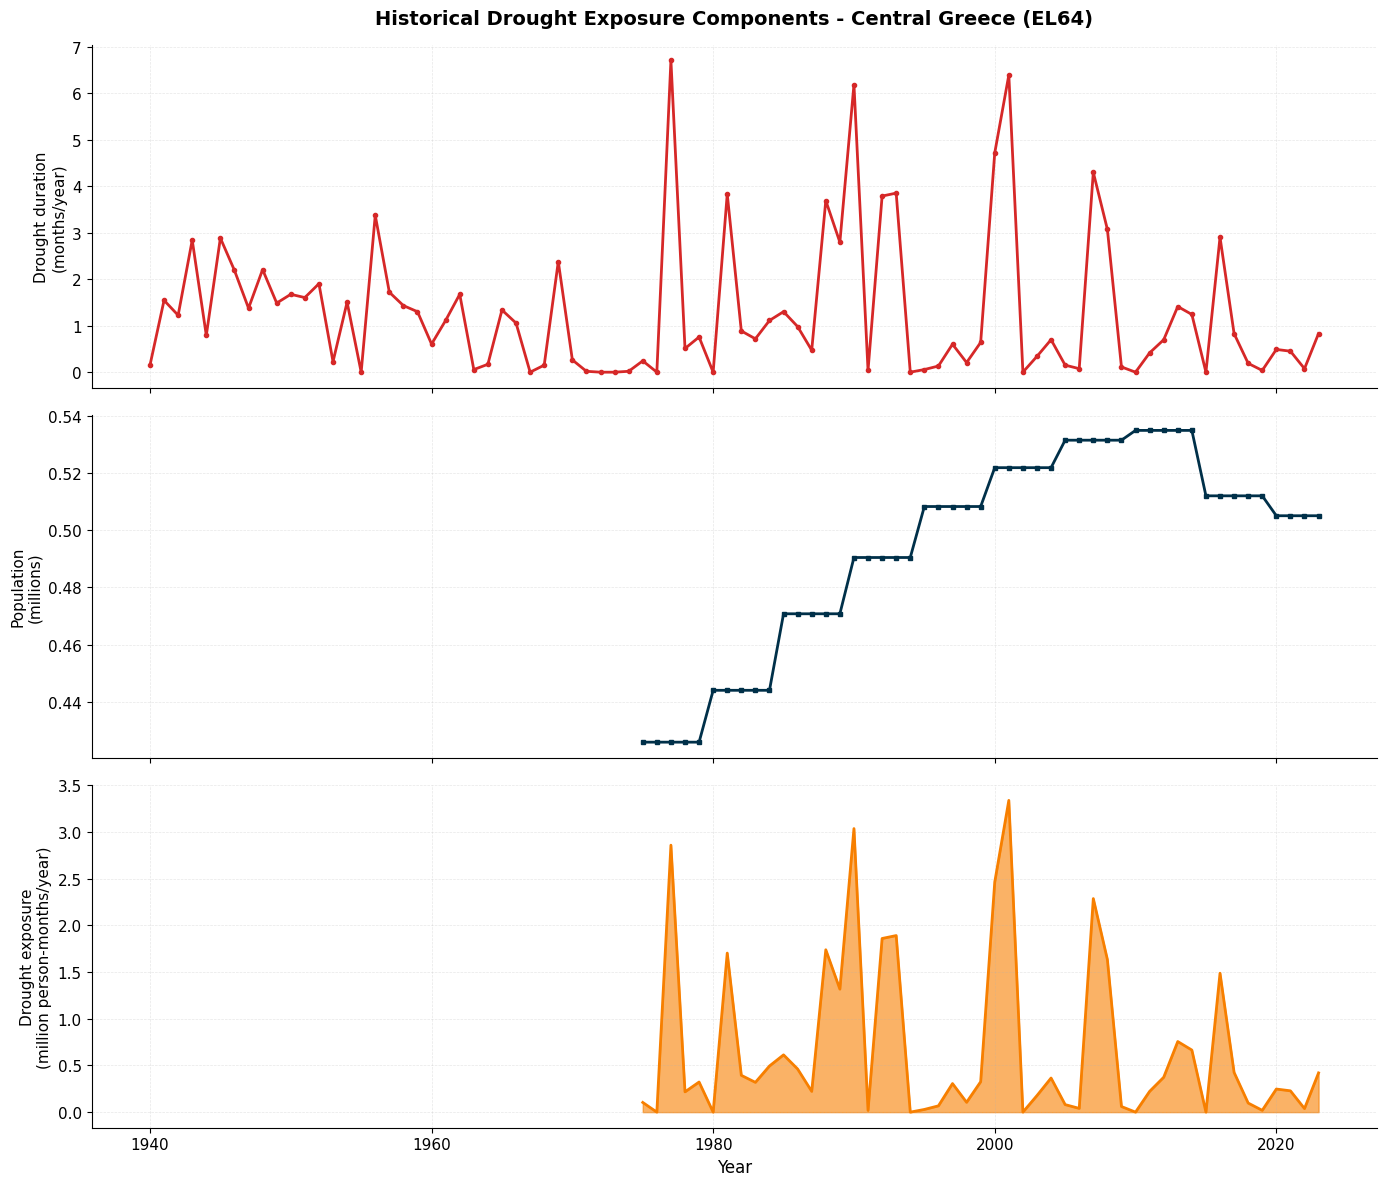


Historical baseline (1991-2020):
  Average drought duration: 1.25 months/year
  Average population: 0.52 million
  Average exposure: 0.64 million person-months/year


In [21]:
# Visualize historical exposure components
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Panel 1: Drought Duration
axes[0].plot(hist_exposure['year'], hist_exposure['dmd'], 
             color='#D62828', linewidth=2, marker='o', markersize=3)
axes[0].set_ylabel('Drought duration\n(months/year)', fontsize=11)
axes[0].set_title('Historical Drought Exposure Components - Central Greece (EL64)', 
                  fontsize=14, fontweight='bold', pad=15)
axes[0].grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

# Panel 2: Population
axes[1].plot(hist_exposure['year'], hist_exposure['population']/1e6, 
             color='#003049', linewidth=2, marker='s', markersize=3)
axes[1].set_ylabel('Population\n(millions)', fontsize=11)
axes[1].grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

# Panel 3: Drought Exposure
axes[2].fill_between(hist_exposure['year'], 0, hist_exposure['exposure']/1e6,
                     color='#F77F00', alpha=0.6)
axes[2].plot(hist_exposure['year'], hist_exposure['exposure']/1e6, 
             color='#F77F00', linewidth=2)
axes[2].set_ylabel('Drought exposure\n(million person-months/year)', fontsize=11)
axes[2].set_xlabel('Year', fontsize=12)
axes[2].grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

# Calculate baseline statistics
baseline_hist = hist_exposure[
    hist_exposure['year'].between(baseline_start, baseline_end)
]

print(f"\nHistorical baseline ({baseline_start}-{baseline_end}):")
print(f"  Average drought duration: {baseline_hist['dmd'].mean():.2f} months/year")
print(f"  Average population: {baseline_hist['population'].mean()/1e6:.2f} million")
print(f"  Average exposure: {baseline_hist['exposure'].mean()/1e6:.2f} million person-months/year")

*Figure: Historical drought exposure components for Central Greece (EL64), 1975–2020. Panels show annual drought duration (top), population (middle), and total drought exposure (the product of duration and population (bottom)).*

```{admonition} Key Insight
:class: tip
Here we define drought exposure as the product of hazard and population. In Central Greece, a declining population partially offsets the increase in drought duration, illustrating why both components must be tracked together rather than in isolation.
```

## Part 2: Future Drought Exposure Under Climate Change

Now we project future drought exposure by combining:
- **Climate model projections** of drought duration (multiple models × 2 RCP scenarios)
- **Population projections** from GHS-WUP (up to 2100)

We'll examine both RCP4.5 (moderate emissions) and RCP8.5 (high emissions) scenarios.

### RCP4.5 Scenario (Moderate Emissions)

For each RCP scenario, we compute the multi-model ensemble statistics (median, 17th and 83rd percentiles) and merge with population projections to derive ensemble exposure statistics.

In [22]:
# Prepare RCP4.5 projections
rcp45_df = drought_proj_df[drought_proj_df['scenario'] == 'RCP4_5'].copy()

# Merge with population for each model
rcp45_exposure = rcp45_df.merge(pop_df_filled, on='year', how='inner')
rcp45_exposure['exposure'] = rcp45_exposure['dmd'] * rcp45_exposure['population']

print(f"RCP4.5 projections: {rcp45_exposure['year'].min()}-{rcp45_exposure['year'].max()}")
print(f"Models: {rcp45_exposure['model'].nunique()}")

# Calculate multi-model statistics by year
rcp45_stats = rcp45_exposure.groupby('year').agg({
    'exposure': ['median', lambda x: np.percentile(x, 17), lambda x: np.percentile(x, 83)],
    'dmd' : ['median', lambda x: np.percentile(x, 17), lambda x: np.percentile(x, 83)]
}).reset_index()
rcp45_stats.columns = ['year', 'exposure_median', 'exposure_p17', 'exposure_p83', 'dmd_median', 'dmd_p17', 'dmd_p83']

rcp45_stats.head()

RCP4.5 projections: 1950-2100
Models: 9


,year,exposure_median,exposure_p17,exposure_p83,dmd_median,dmd_p17,dmd_p83
0,1950,NaN,NaN,NaN,1.321128,1.267696,3.491132
1,1951,NaN,NaN,NaN,0.942527,0.089135,2.464943
2,1952,NaN,NaN,NaN,1.009520,0.866911,2.104689
3,1953,NaN,NaN,NaN,1.568839,0.514251,3.397299
4,1954,NaN,NaN,NaN,0.652194,0.070744,2.045953


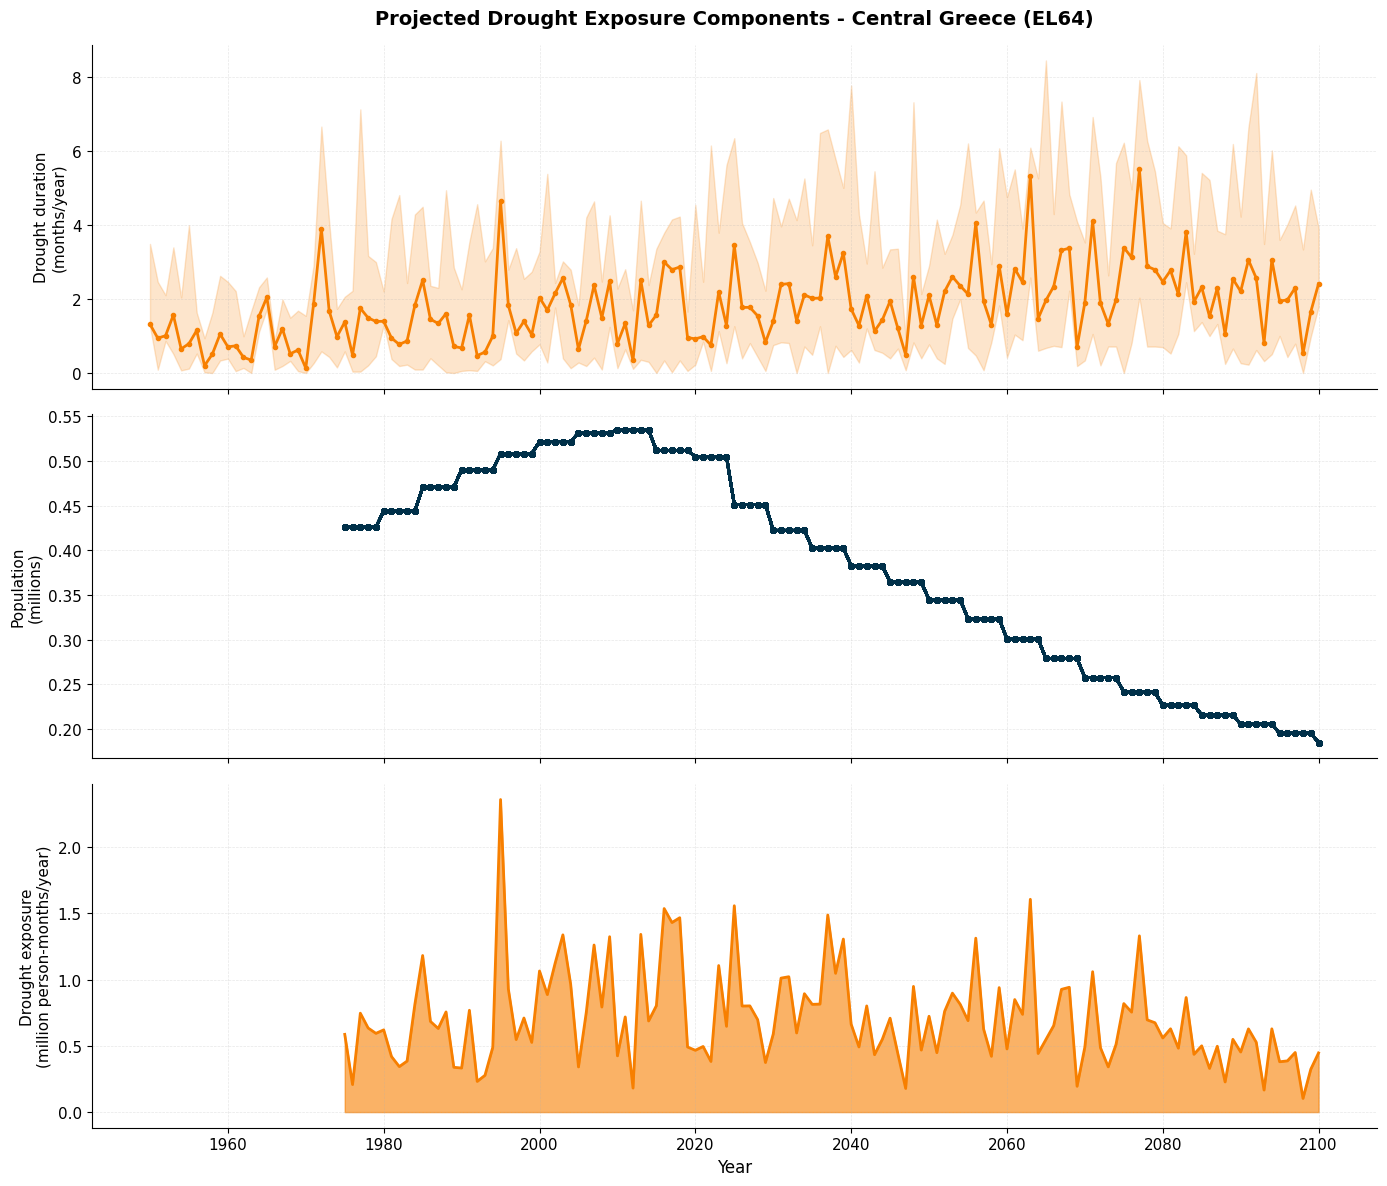

In [23]:
# Visualize projected exposure components
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Panel 1: Drought Duration
axes[0].plot(rcp45_stats['year'], rcp45_stats['dmd_median'], 
             color='#F77F00', linewidth=2, marker='o', markersize=3)
axes[0].set_ylabel('Drought duration\n(months/year)', fontsize=11)
axes[0].set_title('Projected Drought Exposure Components - Central Greece (EL64)', 
                  fontsize=14, fontweight='bold', pad=15)
axes[0].grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
# Add uncertainty range
axes[0].fill_between(rcp45_stats['year'], 
                rcp45_stats['dmd_p17'],
                rcp45_stats['dmd_p83'],
                color='#F77F00', alpha=0.2, label='RCP4.5 (17th-83rd percentile)')

# Panel 2: Population
axes[1].plot(rcp45_exposure['year'], rcp45_exposure['population']/1e6, 
             color='#003049', linewidth=2, marker='s', markersize=3)
axes[1].set_ylabel('Population\n(millions)', fontsize=11)
axes[1].grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

# Panel 3: Drought Exposure
axes[2].fill_between(rcp45_stats['year'], 0, rcp45_stats['exposure_median']/1e6,
                     color='#F77F00', alpha=0.6)
axes[2].plot(rcp45_stats['year'], rcp45_stats['exposure_median']/1e6, 
             color='#F77F00', linewidth=2)
axes[2].set_ylabel('Drought exposure\n(million person-months/year)', fontsize=11)
axes[2].set_xlabel('Year', fontsize=12)
axes[2].grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)

plt.tight_layout()
plt.show()



*Figure: Historical drought exposure components for Central Greece (EL64), 1975–2020. Panels show annual drought duration (top), population (middle), and total drought exposure (the product of duration and population (bottom)).*


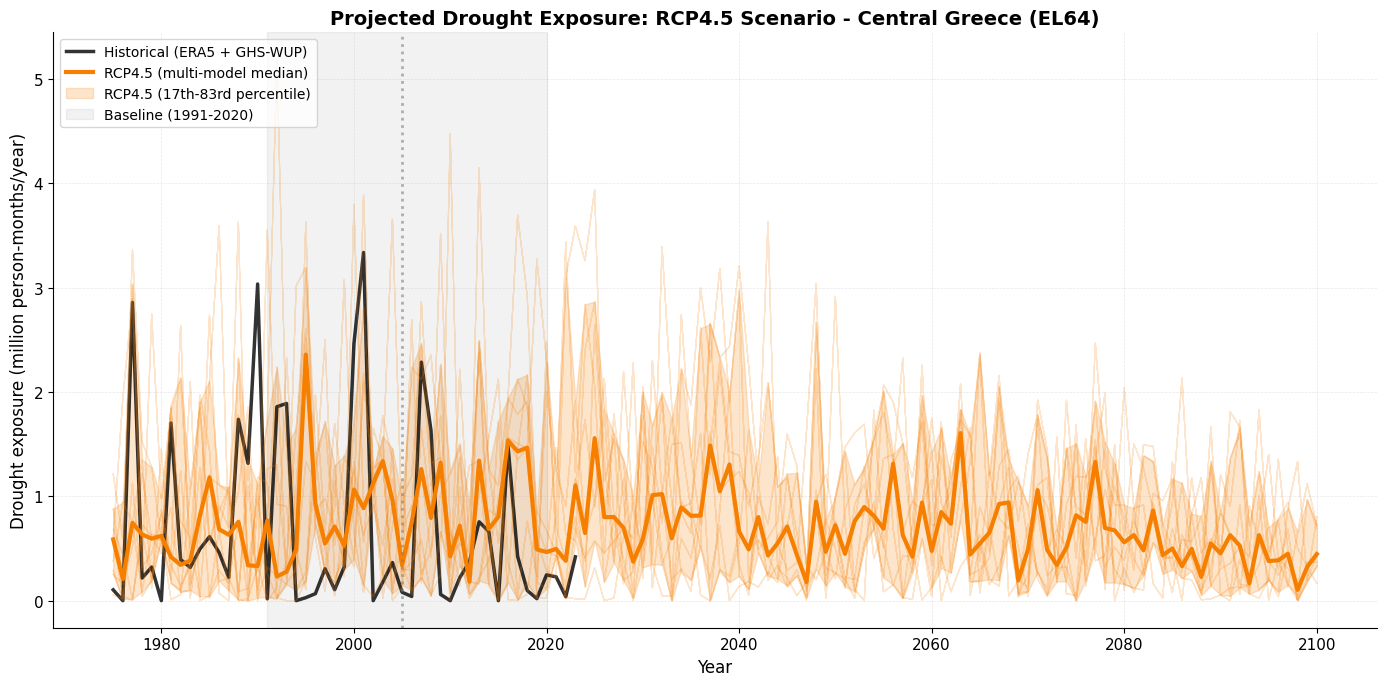

In [24]:
# Visualize RCP4.5 projections
fig, ax = plt.subplots(figsize=(14, 7))

# Plot historical exposure
ax.plot(hist_exposure['year'], hist_exposure['exposure']/1e6,
        color='black', linewidth=2.5, label='Historical (ERA5 + GHS-WUP)', alpha=0.8)

# Plot individual models (light)
for model in rcp45_exposure['model'].unique():
    model_data = rcp45_exposure[rcp45_exposure['model'] == model]
    ax.plot(model_data['year'], model_data['exposure']/1e6,
            color='#F77F00', linewidth=0.8, alpha=0.2)

# Plot multi-model median
ax.plot(rcp45_stats['year'], rcp45_stats['exposure_median']/1e6,
        color='#F77F00', linewidth=3, label='RCP4.5 (multi-model median)')

# Add uncertainty range
ax.fill_between(rcp45_stats['year'], 
                rcp45_stats['exposure_p17']/1e6,
                rcp45_stats['exposure_p83']/1e6,
                color='#F77F00', alpha=0.2, label='RCP4.5 (17th-83rd percentile)')

# Mark transition from historical to projections
ax.axvline(2005, color='gray', linestyle=':', linewidth=2, alpha=0.6)

# Mark baseline period
ax.axvspan(baseline_start, baseline_end, color='gray', alpha=0.1, label=f'Baseline ({baseline_start}-{baseline_end})')

ax.set_xlabel('Year', fontsize=12)
ax.set_ylabel('Drought exposure (million person-months/year)', fontsize=12)
ax.set_title('Projected Drought Exposure: RCP4.5 Scenario - Central Greece (EL64)', 
             fontsize=14, fontweight='bold')
ax.legend(loc='upper left', fontsize=10, frameon=True)
ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()

*Figure: Historical and projected drought exposure for Central Greece (EL64), 1975–2100. Black lines show the observed drought exposure (using ERA5 data) and orange lines and shadings show the modelled drought exposure from 1975–2100. The thick orange line shows the multi-model ensemble median, and the shading the multi-model uncertainty (17–83 percentile).*

```{admonition} Key Insight
:class: tip
The shaded uncertainty band reflects the spread across climate models. While all models agree on the direction of change, the magnitude varies, making a multi-model ensemble essential for robust projections rather than relying on any single model.
```

### RCP8.5 Scenario (High Emissions)

In [25]:
# Prepare RCP8.5 projections
rcp85_df = drought_proj_df[drought_proj_df['scenario'] == 'RCP8_5'].copy()

# Merge with population
rcp85_exposure = rcp85_df.merge(pop_df_filled, on='year', how='inner')
rcp85_exposure['exposure'] = rcp85_exposure['dmd'] * rcp85_exposure['population']

# Calculate multi-model statistics
rcp85_stats = rcp85_exposure.groupby('year').agg({
    'exposure': ['median', lambda x: np.percentile(x, 17), lambda x: np.percentile(x, 83)],
        'dmd' : ['median', lambda x: np.percentile(x, 17), lambda x: np.percentile(x, 83)]
}).reset_index()
rcp85_stats.columns = ['year', 'exposure_median', 'exposure_p17', 'exposure_p83', 'dmd_median', 'dmd_p17', 'dmd_p83']

print(f"RCP8.5 projections: {rcp85_exposure['year'].min()}-{rcp85_exposure['year'].max()}")
print(f"Models: {rcp85_exposure['model'].nunique()}")

RCP8.5 projections: 1950-2100
Models: 9


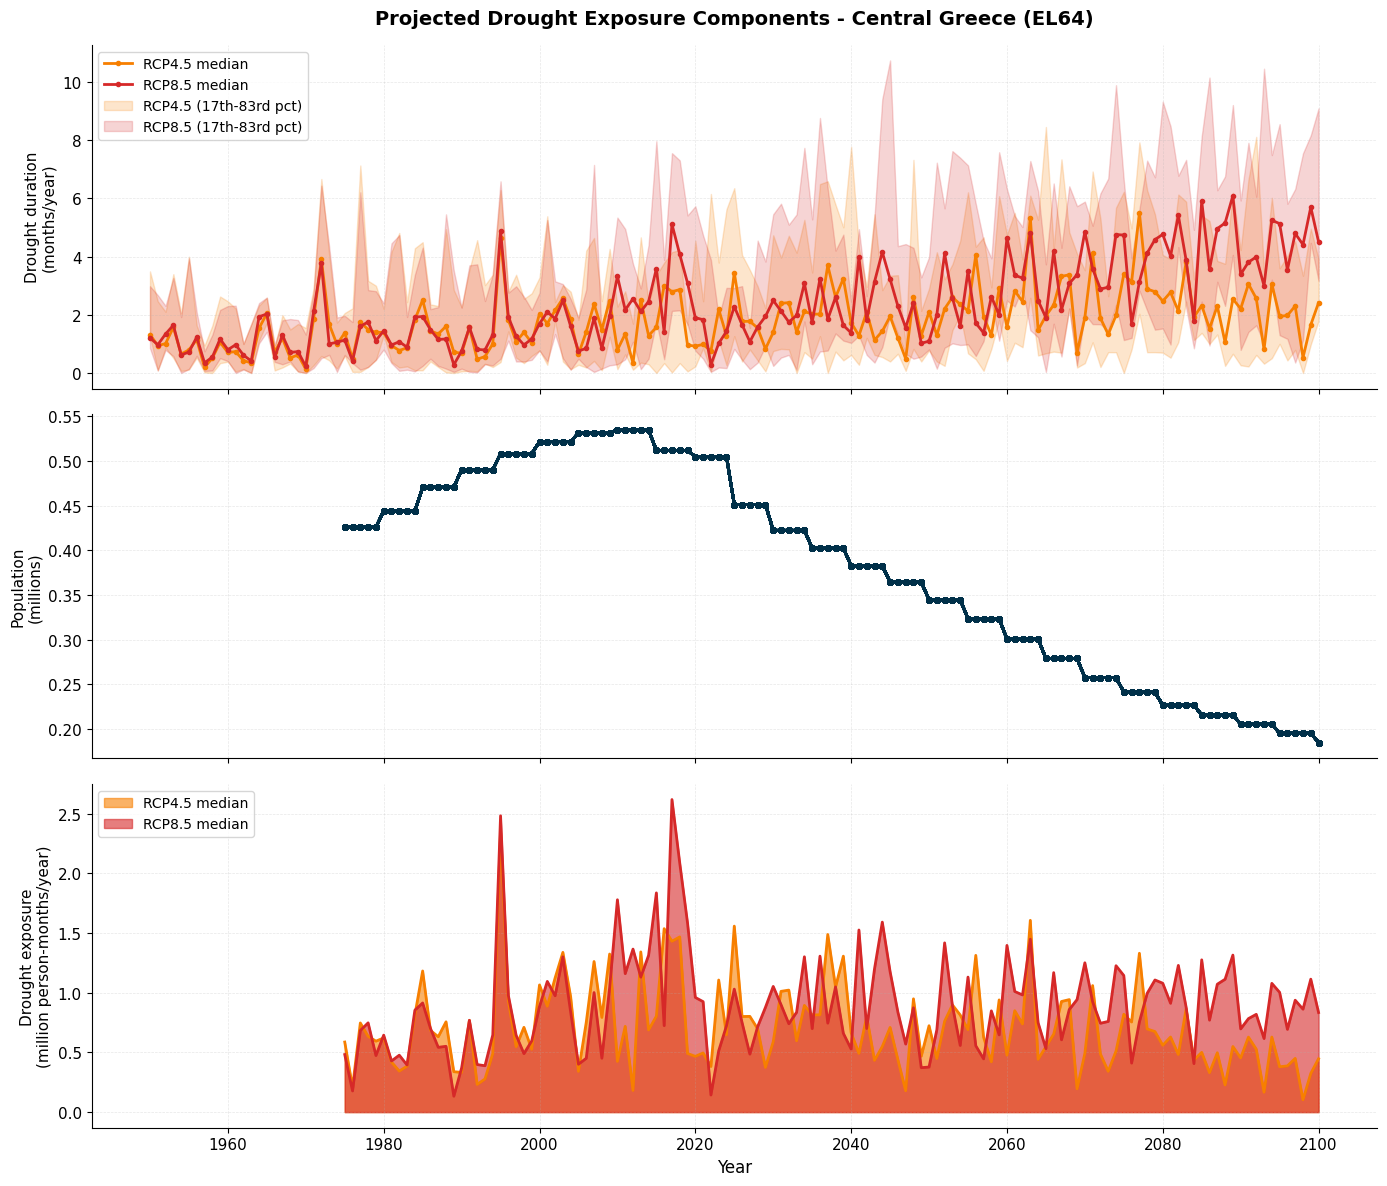

In [26]:
# Visualize projected exposure components
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Panel 1: Drought Duration
axes[0].plot(rcp45_stats['year'], rcp45_stats['dmd_median'], 
             color='#F77F00', linewidth=2, marker='o', markersize=3, label='RCP4.5 median')
axes[0].plot(rcp85_stats['year'], rcp85_stats['dmd_median'], 
             color='#D62828', linewidth=2, marker='o', markersize=3, label='RCP8.5 median')
axes[0].set_ylabel('Drought duration\n(months/year)', fontsize=11)
axes[0].set_title('Projected Drought Exposure Components - Central Greece (EL64)', 
                  fontsize=14, fontweight='bold', pad=15)
axes[0].grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
# Add uncertainty range
axes[0].fill_between(rcp45_stats['year'], 
                rcp45_stats['dmd_p17'],
                rcp45_stats['dmd_p83'],
                color='#F77F00', alpha=0.2, label='RCP4.5 (17th-83rd pct)')
axes[0].fill_between(rcp85_stats['year'], 
                rcp85_stats['dmd_p17'],
                rcp85_stats['dmd_p83'],
                color='#D62828', alpha=0.2, label='RCP8.5 (17th-83rd pct)')
axes[0].legend(loc='upper left', fontsize=10, frameon=True)

# Panel 2: Population
axes[1].plot(rcp45_exposure['year'], rcp45_exposure['population']/1e6, 
             color='#003049', linewidth=2, marker='s', markersize=3)
axes[1].set_ylabel('Population\n(millions)', fontsize=11)
axes[1].grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

# Panel 3: Drought Exposure
axes[2].fill_between(rcp45_stats['year'], 0, rcp45_stats['exposure_median']/1e6,
                     color='#F77F00', alpha=0.6, label='RCP4.5 median')
axes[2].fill_between(rcp85_stats['year'], 0, rcp85_stats['exposure_median']/1e6,
                     color='#D62828', alpha=0.6, label='RCP8.5 median')
axes[2].plot(rcp45_stats['year'], rcp45_stats['exposure_median']/1e6, 
             color='#F77F00', linewidth=2)
axes[2].plot(rcp85_stats['year'], rcp85_stats['exposure_median']/1e6, 
             color='#D62828', linewidth=2)
axes[2].set_ylabel('Drought exposure\n(million person-months/year)', fontsize=11)
axes[2].set_xlabel('Year', fontsize=12)
axes[2].grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)
axes[2].legend(loc='upper left', fontsize=10, frameon=True)

plt.tight_layout()
plt.show()


*Figure: Projected drought exposure components under RCP4.5 and RCP8.5. Panels show drought duration (top), population (middle), and total exposure (bottom). Note the strong year-to-year variability; the next step applies a 30-year rolling mean to better reveal the underlying trend.*

```{admonition} Key Insight
:class: tip
RCP8.5 (high emissions) projects higher drought duration and exposure than RCP4.5, with the gap between scenarios widening toward the end of the century. Both hazard and population changes contribute to the overall exposure trajectory.
```

### Smoothing with a 30-year rolling mean

Year-to-year drought variability makes it hard to read the long-term signal. The cell below applies a 30-year rolling mean to drought duration for each model before computing exposure, revealing the underlying climate-driven trend.

In [27]:
# Prepare RCP8.5 projections
rcp45_df_rm = drought_proj_df[drought_proj_df['scenario'] == 'RCP4_5'].copy()

# Calculate rolling mean for drought duration (3-year window) to smooth projections
window=30
rcp45_df_rm['dmd'] = rcp45_df_rm.groupby('model')['dmd'].transform(lambda x: x.rolling(window=window, center=True, min_periods=1).mean())

# Merge with population
rcp45_exposure_rm = rcp45_df_rm.merge(pop_df_filled, on='year', how='inner')
rcp45_exposure_rm['exposure'] = rcp45_exposure_rm['dmd'] * rcp45_exposure_rm['population']

# Calculate multi-model statistics
rcp45_stats_rm = rcp45_exposure_rm.groupby('year').agg({
    'exposure': ['median', lambda x: np.percentile(x, 17), lambda x: np.percentile(x, 83)],
        'dmd' : ['median', lambda x: np.percentile(x, 17), lambda x: np.percentile(x, 83)]
}).reset_index()
rcp45_stats_rm.columns = ['year', 'exposure_median', 'exposure_p17', 'exposure_p83', 'dmd_median', 'dmd_p17', 'dmd_p83']

print(f"RCP4.5 projections: {rcp45_exposure_rm['year'].min()}-{rcp45_exposure_rm['year'].max()}")
print(f"Models: {rcp45_exposure_rm['model'].nunique()}")


# Prepare RCP8.5 projections
rcp85_df_rm = drought_proj_df[drought_proj_df['scenario'] == 'RCP8_5'].copy()

# Calculate rolling mean for drought duration (3-year window) to smooth projections
window=30
rcp85_df_rm['dmd'] = rcp85_df_rm.groupby('model')['dmd'].transform(lambda x: x.rolling(window=window, center=True, min_periods=1).mean())

# Merge with population
rcp85_exposure_rm = rcp85_df_rm.merge(pop_df_filled, on='year', how='inner')
rcp85_exposure_rm['exposure'] = rcp85_exposure_rm['dmd'] * rcp85_exposure_rm['population']

# Calculate multi-model statistics
rcp85_stats_rm = rcp85_exposure_rm.groupby('year').agg({
    'exposure': ['median', lambda x: np.percentile(x, 17), lambda x: np.percentile(x, 83)],
        'dmd' : ['median', lambda x: np.percentile(x, 17), lambda x: np.percentile(x, 83)]
}).reset_index()
rcp85_stats_rm.columns = ['year', 'exposure_median', 'exposure_p17', 'exposure_p83', 'dmd_median', 'dmd_p17', 'dmd_p83']

print(f"RCP8.5 projections: {rcp85_exposure_rm['year'].min()}-{rcp85_exposure_rm['year'].max()}")
print(f"Models: {rcp85_exposure_rm['model'].nunique()}")

RCP4.5 projections: 1950-2100
Models: 9
RCP8.5 projections: 1950-2100
Models: 9


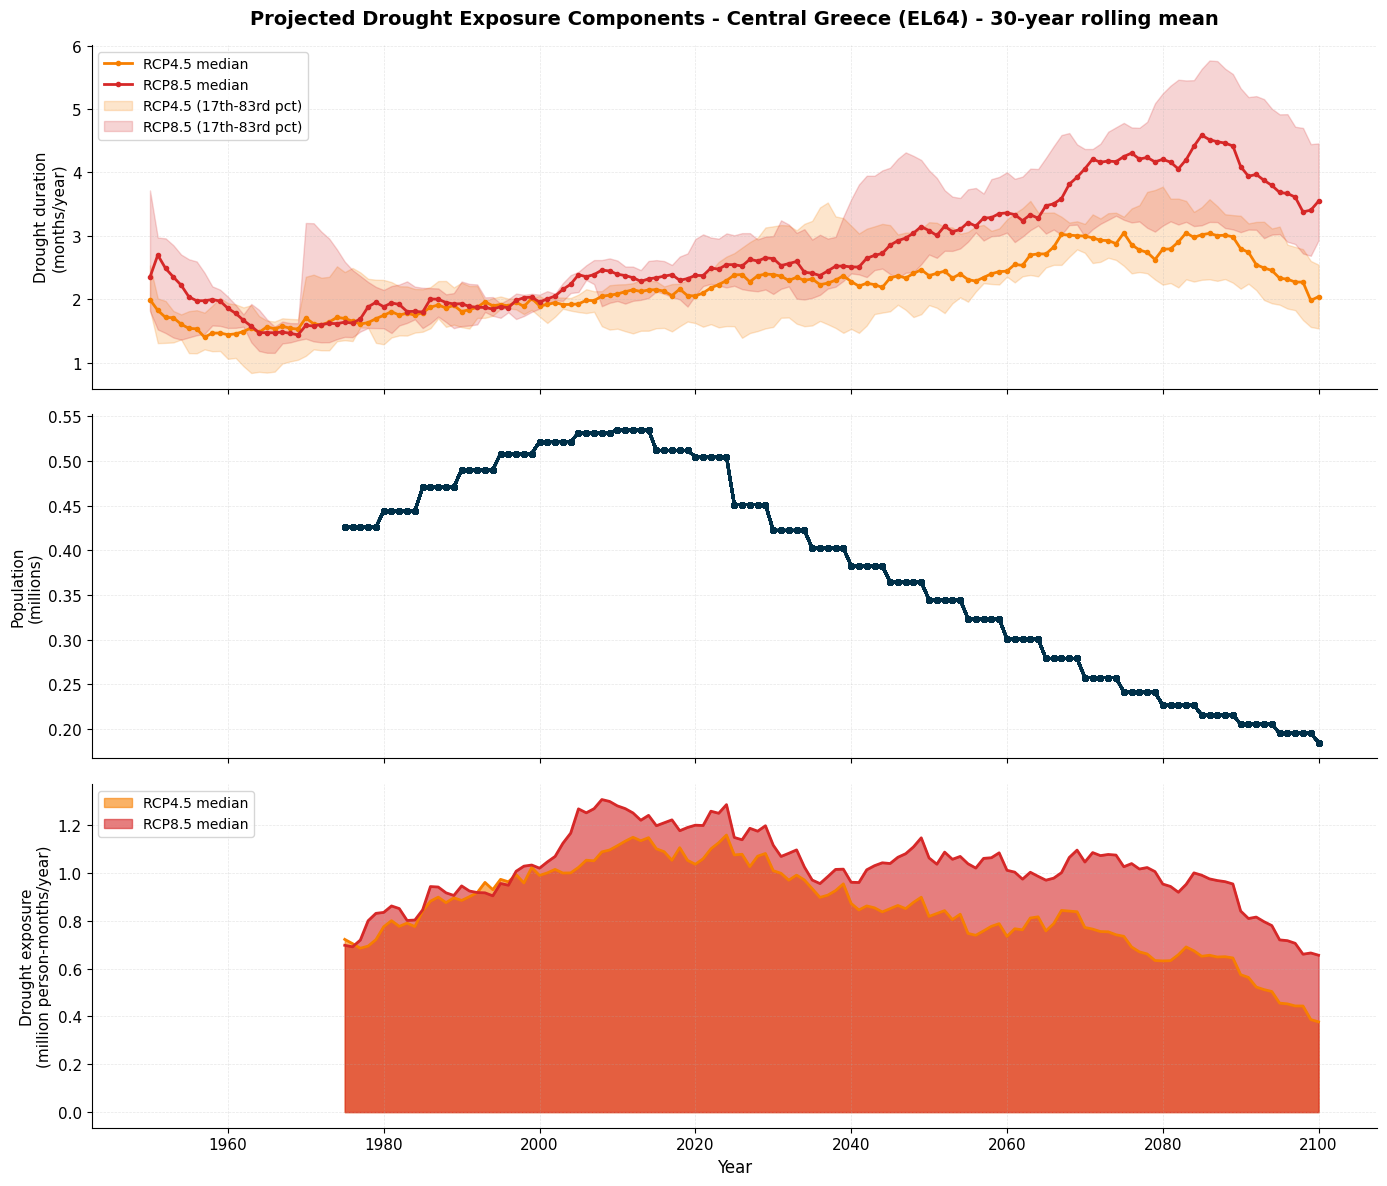

In [28]:
# Visualize projected exposure components
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

# Panel 1: Drought Duration
axes[0].plot(rcp45_stats_rm['year'], rcp45_stats_rm['dmd_median'], 
             color='#F77F00', linewidth=2, marker='o', markersize=3, label='RCP4.5 median')
axes[0].plot(rcp85_stats_rm['year'], rcp85_stats_rm['dmd_median'], 
             color='#D62828', linewidth=2, marker='o', markersize=3, label='RCP8.5 median')
axes[0].set_ylabel('Drought duration\n(months/year)', fontsize=11)
axes[0].set_title('Projected Drought Exposure Components - Central Greece (EL64) - 30-year rolling mean', 
                  fontsize=14, fontweight='bold', pad=15)
axes[0].grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)
# Add uncertainty range
axes[0].fill_between(rcp45_stats['year'], 
                rcp45_stats_rm['dmd_p17'],
                rcp45_stats_rm['dmd_p83'],
                color='#F77F00', alpha=0.2, label='RCP4.5 (17th-83rd pct)')
axes[0].fill_between(rcp85_stats['year'], 
                rcp85_stats_rm['dmd_p17'],
                rcp85_stats_rm['dmd_p83'],
                color='#D62828', alpha=0.2, label='RCP8.5 (17th-83rd pct)')
axes[0].legend(loc='upper left', fontsize=10, frameon=True)

# Panel 2: Population
axes[1].plot(rcp45_exposure_rm['year'], rcp45_exposure_rm['population']/1e6, 
             color='#003049', linewidth=2, marker='s', markersize=3)
axes[1].set_ylabel('Population\n(millions)', fontsize=11)
axes[1].grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

# Panel 3: Drought Exposure
axes[2].fill_between(rcp45_stats_rm['year'], 0, rcp45_stats_rm['exposure_median']/1e6,
                     color='#F77F00', alpha=0.6, label='RCP4.5 median')
axes[2].fill_between(rcp85_stats_rm['year'], 0, rcp85_stats_rm['exposure_median']/1e6,
                     color='#D62828', alpha=0.6, label='RCP8.5 median')
axes[2].plot(rcp45_stats_rm['year'], rcp45_stats_rm['exposure_median']/1e6, 
             color='#F77F00', linewidth=2)
axes[2].plot(rcp85_stats_rm['year'], rcp85_stats_rm['exposure_median']/1e6, 
             color='#D62828', linewidth=2)
axes[2].set_ylabel('Drought exposure\n(million person-months/year)', fontsize=11)
axes[2].set_xlabel('Year', fontsize=12)
axes[2].grid(True, alpha=0.3, linestyle='--', linewidth=0.5)
axes[2].spines['top'].set_visible(False)
axes[2].spines['right'].set_visible(False)
axes[2].legend(loc='upper left', fontsize=10, frameon=True)

plt.tight_layout()
plt.show()


*Figure: Historical and projected drought exposure components for Central Greece (EL64) using a 30-year rolling mean. Panels show annual drought duration (top), population (middle), and total drought exposure (the product of duration and population (bottom)); all using a 30-year rolling mean.*

```{admonition} Key Insight
:class: tip
The 30-year rolling mean makes the long-term trend clearly visible. Under RCP8.5, both drought duration and total exposure increase substantially towards 2100, while RCP4.5 shows a more moderate rise, demonstrating the impact of emission pathway choice on future drought risk.
```

## Near-, mid-, and long-term changes

Those timeseries above are nice, but let's try to get some numbers out of this so that we can communicate a message. Therefore, let's look at three different time periods: 
- Near-term future: 2021–2050
- Mid-term future: 2041–2070
- Long-term future: 2070-2100

### Relative changes with respect to baseline period
Further, let's again evaluate the projections with respect to a baseline period (see best practices outlined in the [tutorial assessing changing drought duration under climate change](../tutorials/changing_drought_duration.ipynb) using the WMO recommended baseline period 1991-2020. To facilitate interpretation, we calculate a factorial change of exposure for the region, and we split the exposure into it's components: relative change of population and drought duration in the near-/mid-/long-term with respect to the baseline period.

#### Understanding the baseline

To better understand the influence of the baseline, let's have a look at the drought duration in the two RCP scenarios over the baseline period (here from 1991–2020). 

2.0011656777028186
2.1831219914551876
516921.6624755524
1035118.126941163
1130665.100971916


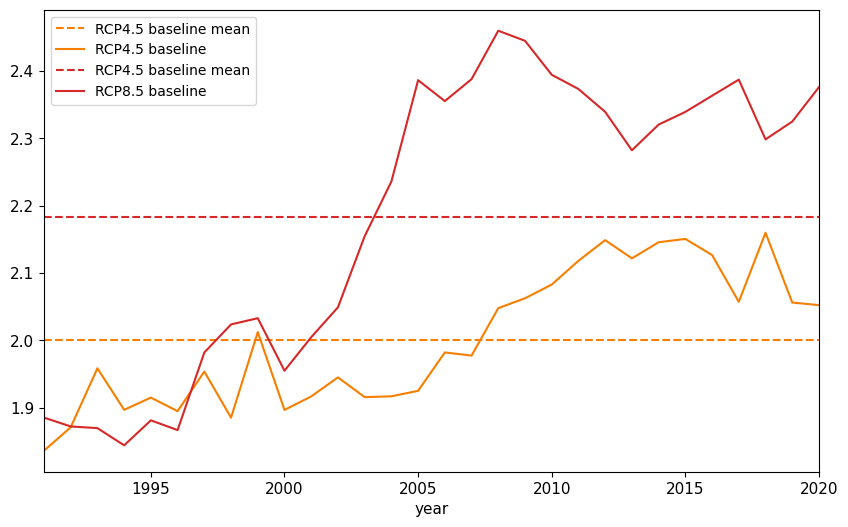

In [ ]:
# Calculate anomalies relative to baseline of RCPs  
baseline_rcp45 = rcp45_stats_rm[rcp45_stats_rm['year'].between(baseline_start, baseline_end)]
baseline_rcp85 = rcp85_stats_rm[rcp85_stats_rm['year'].between(baseline_start, baseline_end)]
baseline_rcp45_dmd = baseline_rcp45['dmd_median'].mean()
baseline_rcp85_dmd = baseline_rcp85['dmd_median'].mean()
baseline_population = pop_df_filled[pop_df_filled['year'].between(baseline_start, baseline_end)]['population'].mean()
baseline_rcp45_exposure = baseline_rcp45['exposure_median'].mean() 
baseline_rcp85_exposure = baseline_rcp85['exposure_median'].mean()

figure, ax = plt.subplots(figsize=(10, 6))
ax.hlines(baseline_rcp45_dmd, xmin=baseline_start, xmax=baseline_end, color='#F77F00', linestyle='--', label='RCP4.5 baseline mean')
baseline_rcp45.plot(x='year', y='dmd_median', label='RCP4.5 baseline', ax=ax, color='#F77F00')
ax.hlines(baseline_rcp85_dmd, xmin=baseline_start, xmax=baseline_end, color='#D62828', linestyle='--', label='RCP4.5 baseline mean')
baseline_rcp85.plot(x='year', y='dmd_median', label='RCP8.5 baseline', ax=ax, color='#D62828')
ax.set_xlim(1991, 2020)
legend = ax.legend(loc='upper left', fontsize=10, frameon=True)

*Figure: Smoothed drought duration (30-year rolling mean) for RCP4.5 and RCP8.5 over the 1991–2020 baseline period. Dashed lines show the scenario-specific baseline means used to compute relative changes in the analysis below.*

### Statistics with respect to the baseline

We express changes as **multiplicative factors** relative to the 1991–2020 baseline. A factor of 1.0 means no change; a factor of 1.5 means a 50% increase. We compute three factors separately for each climate model and future period:

- **Population factor**: ratio of projected population to baseline population (same for both RCP scenarios, since population projections do not depend on emissions)
- **Hazard factor**: ratio of mean projected drought duration to the baseline drought duration, per model
- **Exposure factor**: product of the hazard factor and the population factor; represents the combined change in drought exposure relative to baseline

Separating these factors helps identify whether changes in exposure are driven primarily by the climate (hazard) or by demographic trends (population).

In [37]:
# Compute per-model change factors (relative to 1991-2020 baseline) for boxplot
period_order = ['Near-term', 'Mid-term', 'Long-term']


period_info = [
    ('2071-01-01', '2099-12-31', 'Long-term 2071-2100', 0.97),
    ('2041-01-01', '2069-12-31', 'Mid-term 2041-2070', 0.92),
    ('2021-01-01', '2049-12-31', 'Near-term 2021-2050', 0.87)
]
factor_periods = {
    'Near-term': (2021, 2050),
    'Mid-term':  (2041, 2070),
    'Long-term': (2071, 2100),
}

# Baseline: per-model mean dmd over 1991-2020 (averaged across scenarios)
baseline_dmd_models = (
    drought_proj_df[drought_proj_df['year'].between(baseline_start, baseline_end)]
    .groupby(['model', 'scenario'])['dmd'].mean()
    .reset_index()
    .groupby('model')['dmd'].mean()
    .reset_index()
    .rename(columns={'dmd': 'baseline_dmd'})
)

baseline_pop_median = pop_df[
    pop_df['year'].between(baseline_start, baseline_end)
]['population'].median()

period_results = {}

for period_name, (start, end) in factor_periods.items():
    period_pop_median = pop_df[pop_df['year'].between(start, end)]['population'].median()
    population_factor = np.array([period_pop_median / baseline_pop_median])

    hazard_rcp45, hazard_rcp85 = [], []
    exposure_rcp45, exposure_rcp85 = [], []

    for scenario, h_list, e_list in [
        ('RCP4_5', hazard_rcp45, exposure_rcp45),
        ('RCP8_5', hazard_rcp85, exposure_rcp85),
    ]:
        period_dmd = (
            drought_proj_df[
                drought_proj_df['year'].between(start, end) &
                (drought_proj_df['scenario'] == scenario)
            ]
            .groupby('model')['dmd'].mean()
            .reset_index()
            .rename(columns={'dmd': 'period_dmd'})
        )
        m = period_dmd.merge(baseline_dmd_models, on='model')
        m['hazard_factor']   = m['period_dmd'] / m['baseline_dmd']
        m['exposure_factor'] = (m['period_dmd'] * period_pop_median) / (m['baseline_dmd'] * baseline_pop_median)

        h_list.extend(m['hazard_factor'].values)
        e_list.extend(m['exposure_factor'].values)

    period_results[period_name] = {
        'population_factor': population_factor,
        'hazard_rcp45':      np.array(hazard_rcp45),
        'hazard_rcp85':      np.array(hazard_rcp85),
        'exposure_rcp45':    np.array(exposure_rcp45),
        'exposure_rcp85':    np.array(exposure_rcp85),
    }

print("Period results computed:")
for period_name, res in period_results.items():
    print(f"  {period_name}:")
    print(f"    Population factor:        {res['population_factor'][0]:.3f}")
    print(f"    Hazard RCP4.5 (median):   {np.median(res['hazard_rcp45']):.3f}")
    print(f"    Hazard RCP8.5 (median):   {np.median(res['hazard_rcp85']):.3f}")
    print(f"    Exposure RCP4.5 (median): {np.median(res['exposure_rcp45']):.3f}")
    print(f"    Exposure RCP8.5 (median): {np.median(res['exposure_rcp85']):.3f}")


Period results computed:
  Near-term:
    Population factor:        0.779
    Hazard RCP4.5 (median):   1.033
    Hazard RCP8.5 (median):   1.058
    Exposure RCP4.5 (median): 0.805
    Exposure RCP8.5 (median): 0.824
  Mid-term:
    Population factor:        0.626
    Hazard RCP4.5 (median):   1.255
    Hazard RCP8.5 (median):   1.349
    Exposure RCP4.5 (median): 0.785
    Exposure RCP8.5 (median): 0.844
  Long-term:
    Population factor:        0.418
    Hazard RCP4.5 (median):   1.544
    Hazard RCP8.5 (median):   1.982
    Exposure RCP4.5 (median): 0.645
    Exposure RCP8.5 (median): 0.828


Now, let's plot these and include some uncertainty estimates!

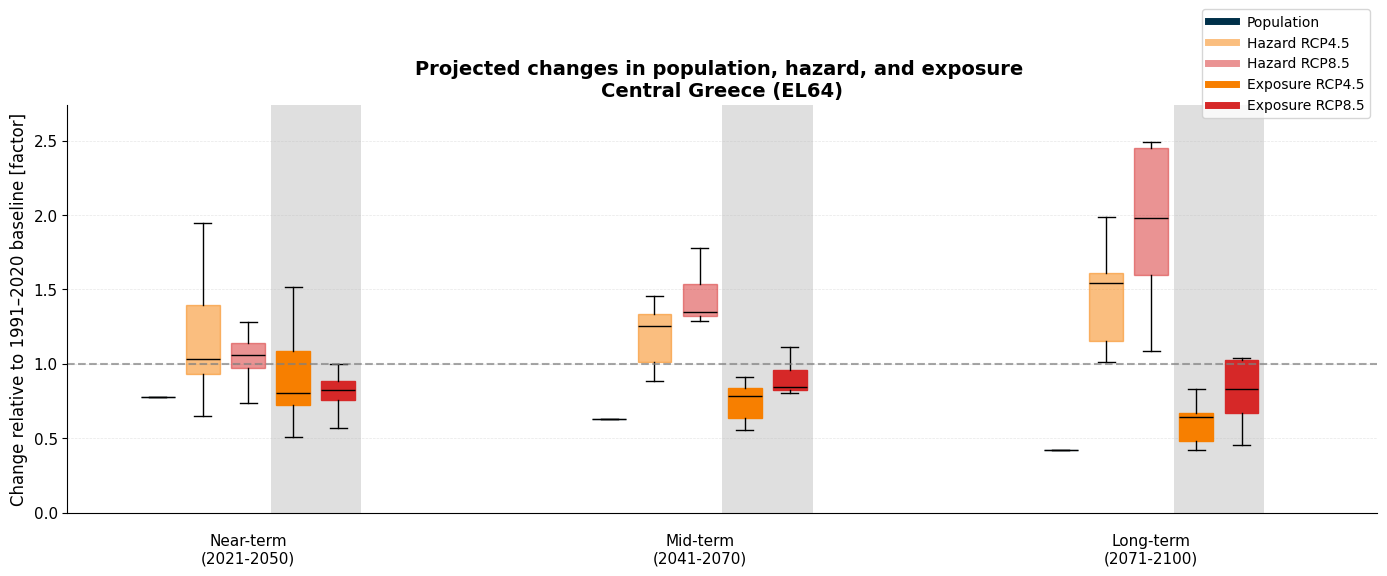

In [38]:
# Extended time-series factor boxplots: add exposure factors (RCP4.5 and RCP8.5)
# Population, Hazard RCP4.5, Hazard RCP8.5, Exposure RCP4.5, Exposure RCP8.5

data_to_plot_exp = []
labels_exp = []
box_colors_exp = []

period_info = [
    ('2071-01-01', '2099-12-31', 'Long-term 2071-2100', 0.97),
    ('2041-01-01', '2069-12-31', 'Mid-term 2041-2070', 0.92),
    ('2021-01-01', '2049-12-31', 'Near-term 2021-2050', 0.87)
]

for period_name in period_order:

    res = period_results[period_name]

    data_to_plot_exp.extend([
        res['population_factor'],
        res['hazard_rcp45'],
        res['hazard_rcp85'],
        res['exposure_rcp45'],
        res['exposure_rcp85'],
    ])

    labels_exp.extend([
        f'{period_name}\nPopulation',
        f'{period_name}\nHazard RCP4.5',
        f'{period_name}\nHazard RCP8.5',
        f'{period_name}\nExposure RCP4.5',
        f'{period_name}\nExposure RCP8.5',
    ])

    # Colors: keep population and hazard colored, exposure with grey background

    box_colors_exp.extend([
        '#003049',      # population
        "#F77F00",      # hazard RCP4.5
        '#D62828',      # hazard RCP8.5
        '#F77F00',      # exposure RCP4.5 (grey background)
        '#D62828',      # exposure RCP8.5 (grey background)
    ])

fig, ax = plt.subplots(figsize=(14, 6))

x_positions = [1.1, 1.2, 1.3, 1.4, 1.5, 2.1, 2.2, 2.3, 2.4, 2.5, 3.1, 3.2, 3.3, 3.4, 3.5]
# grey highlighted backgrounds for exposure boxes
# near term: 1.4-1.5, mid term: 2.4-2.5, long term: 3.4-3.5
for x_start in [1.35, 2.35, 3.35]:
    left, bottom, width, height = (x_start, -1, 0.2, 5)
    rect = plt.Rectangle((left, bottom), width, height,
                         facecolor="grey", alpha=0.25)
    ax.add_patch(rect)

bp_exp = ax.boxplot(
    data_to_plot_exp,
    tick_labels=None,
    patch_artist=True,
    widths=0.075,
    showfliers=False,
    boxprops=dict(linewidth=1.0),
    medianprops=dict(color='black', linewidth=1.0),
    whiskerprops=dict(linewidth=1.0),
    capprops=dict(linewidth=1.0),
    positions=x_positions
)
ax.set_xlim(0.9, 3.8)
ax.set_ylim(0, max([max(d) for d in data_to_plot_exp]) * 1.1)
ii=0
for patch, color in zip(bp_exp['boxes'], box_colors_exp):
    patch.set_facecolor(color)
    # use different alpha for exposure boxes to make them look like they are on top of the grey background
    patch.set_alpha(1) if ii in [3, 4, 8, 9, 13, 14] else patch.set_alpha(0.5)
    #patch.set_alpha(0.7)
    patch.set_edgecolor(color)
    ii += 1


# Reference line: no change
ax.axhline(1.0, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)
ax.set_ylabel('Change relative to 1991–2020 baseline [factor]', fontsize=12)
ax.set_title(
    'Projected changes in population, hazard, and exposure \nCentral Greece (EL64)',
    fontsize=14,
    fontweight='bold',
)

ax.grid(True, axis='y', alpha=0.3, linestyle='--', linewidth=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
# add a legend instead of xticklabels
legend_elements = [
    plt.Line2D([0], [0], color='#003049', lw=5, label='Population'),
    plt.Line2D([0], [0], color='#F77F00', lw=5, alpha=0.5, label='Hazard RCP4.5'),
    plt.Line2D([0], [0], color='#D62828', lw=5, alpha=0.5, label='Hazard RCP8.5'),
    plt.Line2D([0], [0], color='#F77F00', lw=5, alpha=1, label='Exposure RCP4.5'),
    plt.Line2D([0], [0], color='#D62828', lw=5, alpha=1, label='Exposure RCP8.5'),
]
ax.legend(handles=legend_elements, loc='center right', bbox_to_anchor=(1, 1.1), fontsize=10, frameon=True)
# remove x-axis ticks and labels
ax.set_xticks([])
# place x-axis labels manually with rotation at the center of each group just entitled "near-term", "mid-term", "long-term"
ax.text(1.3, -0.25, 'Near-term\n(2021-2050)', ha='center', va='center', fontsize=11)
ax.text(2.3, -0.25, 'Mid-term\n(2041-2070)', ha='center', va='center', fontsize=11)
ax.text(3.3, -0.25, 'Long-term\n(2071-2100)', ha='center', va='center', fontsize=11)
#plt.setp(ax.get_xticklabels(), rotation=25, ha='right')

plt.tight_layout()
plt.show()


*Figure: Projected change factors for population (blue), hazard (semi-transparent), and exposure (solid) relative to the 1991–2020 baseline, for near-, mid-, and long-term periods, using RCP4.5 (orange) amnd RCP8.5 (red) scenarios. Each box shows the model spread (25th–75th percentile), whiskers the full range. The grey-shaded boxes highlight the exposure factor, which combines both hazard and population change. Note that the population data does not show any uncertainty.*

```{admonition} Key Insight
:class: tip
The exposure factor compounds hazard and population change. Even where population is projected to decline, a strong increase in drought hazard can still drive net exposure increases, particularly under RCP8.5 in the long-term. This highlights that reducing emissions (i.e., staying on RCP4.5) is the most effective lever for limiting future exposure.
```

### End-of-Century exposure

We've now seen the factorial change for the near-, mid- and long-term future. Let's now extract some (absolute) numbers for long-term future. 

In [39]:
# Calculate baseline exposure (1991-2020) from climate models
baseline_models = drought_proj_df[
    drought_proj_df['year'].between(baseline_start, baseline_end)
].groupby(['model', 'scenario'])[['year', 'dmd']].median().reset_index()

baseline_pop = pop_df[
    pop_df['year'].between(baseline_start, baseline_end)
]['population'].median()

baseline_models['exposure'] = baseline_models['dmd'] * baseline_pop

# Calculate end-of-century exposure (2071-2100)
eoc_models = drought_proj_df[
    drought_proj_df['year'].between(2071, 2100)
].groupby(['model', 'scenario'])[['year', 'dmd']].median().reset_index()

eoc_pop = pop_df[
    pop_df['year'].between(2071, 2100)
]['population'].median()

eoc_models['exposure'] = eoc_models['dmd'] * eoc_pop

# Merge and calculate changes
changes = eoc_models.merge(baseline_models, on=['model', 'scenario'], suffixes=('_eoc', '_baseline'))
changes['exposure_change'] = changes['exposure_eoc'] - changes['exposure_baseline']
changes['exposure_change_pct'] = (changes['exposure_change'] / changes['exposure_baseline']) * 100

# Summarize by scenario
print("="*80)
print(f"DROUGHT EXPOSURE PROJECTIONS: END-OF-CENTURY (2071-2100)")
print(f"Baseline period: {baseline_start}-{baseline_end}")
print("="*80)

print(f"\nBaseline ({baseline_start}-{baseline_end}):")
print(f"  Population: {baseline_pop/1e6:.2f} million")
baseline_exp = baseline_models.groupby('scenario')['exposure'].median().mean()
print(f"  Drought exposure: {baseline_exp/1e6:.2f} million person-months/year")

print(f"\nEnd-of-century (2071-2100):")
print(f"  Projected population: {eoc_pop/1e6:.2f} million")

for scenario in ['RCP4_5', 'RCP8_5']:
    scenario_changes = changes[changes['scenario'] == scenario]
    
    exp_median = scenario_changes['exposure_eoc'].median()
    exp_p17 = scenario_changes['exposure_eoc'].quantile(0.17)
    exp_p83 = scenario_changes['exposure_eoc'].quantile(0.83)
    
    change_median = scenario_changes['exposure_change'].median()
    change_pct_median = scenario_changes['exposure_change_pct'].median()
    
    n_increase = (scenario_changes['exposure_change'] > 0).sum()
    n_total = len(scenario_changes)
    
    print(f"\n  {scenario.replace('_', '.')}:")
    print(f"    Median exposure: {exp_median/1e6:.2f} million person-months/year")
    print(f"    Uncertainty range: {exp_p17/1e6:.2f} - {exp_p83/1e6:.2f} million person-months/year")
    print(f"    Change from baseline: {change_median/1e6:+.2f} million person-months/year ({change_pct_median:+.1f}%)")
    print(f"    Model agreement: {n_increase}/{n_total} models show increase")

print("\n" + "="*80)

DROUGHT EXPOSURE PROJECTIONS: END-OF-CENTURY (2071-2100)
Baseline period: 1991-2020

Baseline (1991-2020):
  Population: 0.52 million
  Drought exposure: 0.89 million person-months/year

End-of-century (2071-2100):
  Projected population: 0.22 million

  RCP4.5:
    Median exposure: 0.54 million person-months/year
    Uncertainty range: 0.32 - 0.72 million person-months/year
    Change from baseline: -0.33 million person-months/year (-35.2%)
    Model agreement: 2/9 models show increase

  RCP8.5:
    Median exposure: 0.98 million person-months/year
    Uncertainty range: 0.73 - 1.12 million person-months/year
    Change from baseline: -0.15 million person-months/year (-13.8%)
    Model agreement: 4/9 models show increase



```{admonition} Key Insight
:class: tip
By end-of-century (2071–2100), drought exposure is projected to increase substantially under both scenarios relative to the 1991–2020 baseline. The difference between RCP4.5 and RCP8.5 is large — illustrating that emission pathway choice is the single most important determinant of future drought exposure. Notably, even where population is projected to decline, the hazard increase under RCP8.5 can more than compensate, resulting in higher absolute exposure.
```

### Threshold-Based Exposure Analysis

Instead of looking at total drought exposure, we can examine how many people are exposed to significant drought increases over 30-year periods. This approach:

- Calculates cumulative drought months for each 30-year period (baseline: 1991-2020, future: 2021-2050, 2041-2070, 2071-2100)
- Compares future periods to the baseline to identify drought increases
- Evaluates population exposed when increases exceed specific thresholds
- Accounts for model uncertainty by showing the range of projections

This helps answer questions like: "How many people will experience at least 10 additional months of drought per 30-year period compared to the 1991-2020 baseline?"

In [40]:
# Configuration: Define 30-year periods and thresholds
period_length = 30  # years per period
thresholds = [10, 15, 20]  # additional drought months per 30-year period

# Define analysis periods
periods = {
    'Baseline': (1991, 2020),
    'Near-term': (2021, 2050),
    'Mid-term': (2041, 2070),
    'Long-term': (2071, 2100)
}

print(f"Configuration:")
print(f"  Period length: {period_length} years")
print(f"  Thresholds: {thresholds} additional drought months per {period_length}-year period")
print(f"\nAnalysis periods:")
for name, (start, end) in periods.items():
    print(f"  {name}: {start}-{end}")

Configuration:
  Period length: 30 years
  Thresholds: [10, 15, 20] additional drought months per 30-year period

Analysis periods:
  Baseline: 1991-2020
  Near-term: 2021-2050
  Mid-term: 2041-2070
  Long-term: 2071-2100


In [41]:
# Calculate cumulative drought months for each 30-year period
def calculate_period_drought_exposure(drought_df, pop_df, periods, thresholds):
    """Calculate population exposed to drought increases per 30-year period.
    
    Parameters:
    -----------
    drought_df : DataFrame
        Drought projection data
    pop_df : DataFrame
        Population data
    periods : dict
        Dictionary of period names and (start, end) year tuples
    thresholds : list
        List of threshold values for drought month increases
    
    Returns:
    --------
    dict : Results for each threshold containing exposure statistics by period and scenario
    """
    
    # Calculate baseline (1991-2020) cumulative drought for each model
    # Note: Take mean across scenarios for historical period (should be identical)
    baseline_start, baseline_end = periods['Baseline']
    baseline_df = drought_df[
        drought_df['year'].between(baseline_start, baseline_end)
    ].groupby(['model', 'scenario']).agg({
        'dmd': 'sum'  # Total drought months over 30 years
    }).reset_index()
    # Average across scenarios (historical period should be same for both RCPs)
    baseline_df = baseline_df.groupby('model')['dmd'].mean().reset_index()
    baseline_df.rename(columns={'dmd': 'baseline_total'}, inplace=True)
    
    print(f"Baseline cumulative drought ({baseline_start}-{baseline_end}):")
    print(f"  Mean across models: {baseline_df['baseline_total'].mean():.1f} months per {period_length} years")
    print(f"  Range: {baseline_df['baseline_total'].min():.1f} - {baseline_df['baseline_total'].max():.1f} months")
    print(f"  Average per year: {baseline_df['baseline_total'].mean()/period_length:.2f} months/year")
    
    # Calculate cumulative drought for each future period
    results = {threshold: [] for threshold in thresholds}
    
    for period_name, (start, end) in periods.items():
        if period_name == 'Baseline':
            continue
            
        # Calculate total drought months for this period
        period_df = drought_df[
            drought_df['year'].between(start, end)
        ].groupby(['model', 'scenario']).agg({
            'dmd': 'sum'
        }).reset_index()
        period_df.rename(columns={'dmd': 'period_total'}, inplace=True)
        
        # Merge with baseline (baseline is same for all scenarios)
        merged = period_df.merge(baseline_df[['model', 'baseline_total']], 
                                 on='model')
        merged['drought_increase'] = merged['period_total'] - merged['baseline_total']
        
        # Get population for this period (median across years)
        period_pop = pop_df[pop_df['year'].between(start, end)]['population'].median()
        
        # For each threshold, calculate exposure
        for threshold in thresholds:
            # Models where drought increase exceeds threshold
            for scenario in merged['scenario'].unique():
                scenario_data = merged[merged['scenario'] == scenario]
                
                # Count how many models exceed threshold
                exceeds = scenario_data['drought_increase'] >= threshold
                
                # Population exposed (if any model shows exceedance, all population is at risk)
                # We'll calculate the fraction of models that show exceedance
                exposed_models = exceeds.sum()
                total_models = len(scenario_data)
                
                # Store results
                results[threshold].append({
                    'period': period_name,
                    'scenario': scenario,
                    'period_years': f'{start}-{end}',
                    'population': period_pop,
                    'exposed_median': period_pop if exposed_models > total_models/2 else 0,
                    'exposed_min': 0 if exposed_models == 0 else period_pop,
                    'exposed_max': period_pop if exposed_models > 0 else 0,
                    'n_models_exceed': exposed_models,
                    'n_models_total': total_models,
                    'drought_increase_median': scenario_data['drought_increase'].median(),
                    'drought_increase_p17': scenario_data['drought_increase'].quantile(0.17),
                    'drought_increase_p83': scenario_data['drought_increase'].quantile(0.83)
                })
    
    # Convert to DataFrames
    for threshold in thresholds:
        results[threshold] = pd.DataFrame(results[threshold])
    
    return results

# Calculate exposure for all thresholds
threshold_results = calculate_period_drought_exposure(
    drought_proj_df, pop_df, periods, thresholds
)

print(f"\n✓ Threshold-based exposure calculated for {len(thresholds)} thresholds")

Baseline cumulative drought (1991-2020):
  Mean across models: 260.4 months per 30 years
  Range: 213.4 - 307.5 months
  Average per year: 8.68 months/year

✓ Threshold-based exposure calculated for 3 thresholds


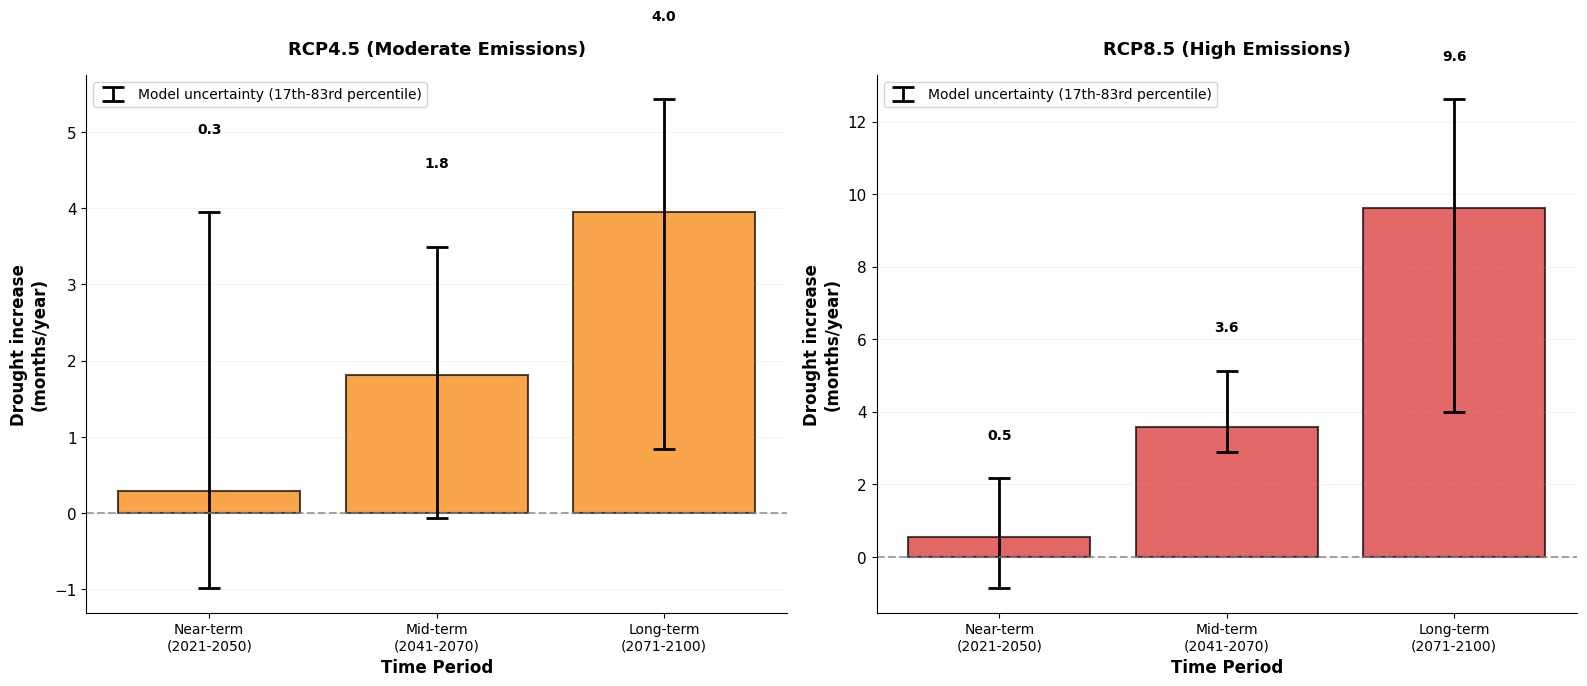

In [42]:
# Visualize drought increase by period with model uncertainty
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

scenarios = ['RCP4_5', 'RCP8_5']
scenario_names = {'RCP4_5': 'RCP4.5 (Moderate Emissions)', 'RCP8_5': 'RCP8.5 (High Emissions)'}
scenario_colors = {'RCP4_5': '#F77F00', 'RCP8_5': '#D62828'}
period_order = ['Near-term', 'Mid-term', 'Long-term']

for idx, scenario in enumerate(scenarios):
    ax = axes[idx]
    
    # Use the first threshold for the main visualization
    threshold = thresholds[0]
    data = threshold_results[threshold]
    scenario_data = data[data['scenario'] == scenario]
    
    # Prepare data for plotting
    x_pos = np.arange(len(period_order))
    medians = []
    errors_lower = []
    errors_upper = []
    
    for period in period_order:
        period_data = scenario_data[scenario_data['period'] == period]
        if len(period_data) > 0:
            median = period_data['drought_increase_median'].values[0]
            p17 = period_data['drought_increase_p17'].values[0]
            p83 = period_data['drought_increase_p83'].values[0]
            
            # Convert to per-year values for clarity
            medians.append(median / period_length)
            errors_lower.append((median - p17) / period_length)
            errors_upper.append((p83 - median) / period_length)
        else:
            medians.append(0)
            errors_lower.append(0)
            errors_upper.append(0)
    
    # Create bar chart
    bars = ax.bar(x_pos, medians, 
                   color=scenario_colors[scenario], alpha=0.7, 
                   edgecolor='black', linewidth=1.5)
    
    # Add error bars
    ax.errorbar(x_pos, medians, 
                yerr=[errors_lower, errors_upper],
                fmt='none', ecolor='black', capsize=8, capthick=2, linewidth=2,
                label='Model uncertainty (17th-83rd percentile)')
    
    # Add horizontal line at zero
    ax.axhline(0, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)
    
    # Customize plot
    ax.set_xlabel('Time Period', fontsize=12, fontweight='bold')
    ax.set_ylabel('Drought increase\n(months/year)', fontsize=12, fontweight='bold')
    ax.set_title(scenario_names[scenario], fontsize=13, fontweight='bold', pad=15)
    ax.set_xticks(x_pos)
    ax.set_xticklabels([f'{p}\n({periods[p][0]}-{periods[p][1]})' for p in period_order], fontsize=10)
    ax.legend(loc='upper left', fontsize=10, frameon=True)
    ax.grid(True, alpha=0.3, linestyle='--', linewidth=0.5, axis='y')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Add value labels on bars
    for i, (bar, val) in enumerate(zip(bars, medians)):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + errors_upper[i] + 1,
                f'{val:.1f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.tight_layout()
plt.show()


*Figure: Projected increase in drought duration (months/year) relative to the 1991–2020 baseline, for near-, mid-, and long-term periods under RCP4.5 (left) and RCP8.5 (right). Error bars show the 17th–83rd percentile range across climate models.*

```{admonition} Key Insight
:class: tip
Projected drought increases grow from near-term to long-term, with RCP8.5 showing much larger changes by 2071–2100. The error bars reflect model uncertainty — an important consideration when planning adaptation measures that need to be robust across a range of possible futures.
```

In [43]:
# Population exposure when drought increases exceed thresholds
print("="*90)
print(f"POPULATION EXPOSURE TO DROUGHT INCREASES")
print(f"(Baseline: {periods['Baseline'][0]}-{periods['Baseline'][1]})")
print("="*90)

for scenario in scenarios:
    print(f"\n{scenario_names[scenario].upper()}")
    print("-"*90)
    
    for period in period_order:
        print(f"\n  {period} ({periods[period][0]}-{periods[period][1]}):")
        
        for threshold in thresholds:
            data = threshold_results[threshold]
            period_data = data[(data['scenario'] == scenario) & (data['period'] == period)]
            
            if len(period_data) > 0:
                pop = period_data['population'].values[0]
                n_exceed = period_data['n_models_exceed'].values[0]
                n_total = period_data['n_models_total'].values[0]
                pct_models = (n_exceed / n_total) * 100
                drought_increase = period_data['drought_increase_median'].values[0]
                
                # Estimate population at risk based on model agreement
                if pct_models > 66:  # Strong agreement (>2/3 models)
                    risk_level = "HIGH"
                    pop_at_risk = pop
                elif pct_models > 33:  # Moderate agreement
                    risk_level = "MODERATE"
                    pop_at_risk = pop * 0.5
                else:  # Weak agreement
                    risk_level = "LOW"
                    pop_at_risk = 0
                
                print(f"    Drought increase ≥ +{threshold} months:")
                print(f"      Model agreement: {n_exceed}/{n_total} models ({pct_models:.0f}%) → Risk: {risk_level}")
                print(f"      Population at risk: {pop_at_risk/1e6:.2f} million ({(pop_at_risk/pop)*100:.0f}% of {pop/1e6:.2f}M)")
                print(f"      Drought increase: {drought_increase:+.1f} months total ({drought_increase/period_length:+.2f} months/year)")

print("\n" + "="*90)
print("\n💡 Interpretation:")
print(f"   - Drought increases show CUMULATIVE additional months over {period_length} years,")
print(f"     relative to {periods['Baseline'][0]}-{periods['Baseline'][1]} baseline")
print(f"   - Example: '+60 months total' = +2.0 months/year average increase")
print(f"   - Population at risk depends on model agreement:")
print(f"     • HIGH (>66% models): All population exposed")
print(f"     • MODERATE (33-66% models): ~50% population exposed")
print(f"     • LOW (<33% models): Minimal exposure")

POPULATION EXPOSURE TO DROUGHT INCREASES
(Baseline: 1991-2020)

RCP4.5 (MODERATE EMISSIONS)
------------------------------------------------------------------------------------------

  Near-term (2021-2050):
    Drought increase ≥ +10 months:
      Model agreement: 4/9 models (44%) → Risk: MODERATE
      Population at risk: 0.20 million (50% of 0.40M)
      Drought increase: +8.6 months total (+0.29 months/year)
    Drought increase ≥ +15 months:
      Model agreement: 4/9 models (44%) → Risk: MODERATE
      Population at risk: 0.20 million (50% of 0.40M)
      Drought increase: +8.6 months total (+0.29 months/year)
    Drought increase ≥ +20 months:
      Model agreement: 4/9 models (44%) → Risk: MODERATE
      Population at risk: 0.20 million (50% of 0.40M)
      Drought increase: +8.6 months total (+0.29 months/year)

  Mid-term (2041-2070):
    Drought increase ≥ +10 months:
      Model agreement: 6/9 models (67%) → Risk: HIGH
      Population at risk: 0.32 million (100% of 0.32M)

```{admonition} Key Insight
:class: tip
The threshold-based analysis translates abstract drought projections into a concrete risk framing: how many people are likely to experience a significant increase in drought? Model agreement matters: when more than two-thirds of models exceed a threshold, confidence in the risk is high. Under RCP8.5 in the long-term, large drought increases are projected with strong model agreement, pointing to a high-risk outcome for the entire population of the region.
```

## Summary

This tutorial demonstrated how to combine drought hazard and population data to estimate drought exposure:

**Historical trends:**
- Historical drought exposure reflects both drought variability and population changes
- ERA5 reanalysis provides observed drought patterns  
- GHS-WUP provides consistent population estimates
- Population gaps filled using persistence (forward fill) for complete timeseries

**Future projections (2021-2100):**
- Climate change is projected to increase drought duration
- Population changes also affect total exposure
- RCP8.5 shows higher exposure than RCP4.5 by end-of-century
- Multi-model ensembles quantify projection uncertainty

**Threshold-based analysis:**
- Identifies population exposed to significant drought increases relative to 1991-2020 baseline
- Uses **cumulative drought months** per 30-year period for clearer long-term trends
- Provides actionable estimates with model uncertainty quantified via error bars
- Accounts for model agreement in assessing exposure risk

**Key takeaways:**
- Exposure = Hazard × Population (both components matter!)
- Multiple climate models are essential for assessing uncertainty
- Different emission scenarios lead to different exposure outcomes
- 30-year cumulative analysis reveals long-term trends more clearly than annual values
- Model agreement provides confidence levels for risk assessment
- Early climate action (RCP4.5) can substantially reduce future drought exposure

**Outlook**

In the example here, we only have one scenario on how population might change - but this, of course, remains uncertain as well and could/should be incorporated in an exposure assessment. To complete a full drought risk assessment, you would also need to incorporate **vulnerability** to represent socioeconomic factors that affect drought impacts. Further, having also data on** **adaptation**, would allow you to evaluate the effectiveness of such measures to reduce exposure or vulnerability.